In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

sns.set_style('darkgrid')
plt.rcParams.update({
    'lines.linewidth': 2,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'axes.labelsize': 14,
    'legend.fontsize': 12,
    'axes.titlesize': 16,
})

In [14]:
train_df = pd.read_csv('/scratch/storage0/ce20b049/Ishita/FineTuning_DDP/Modular/Final/csvs/FIL_No shuffle.csv')

In [15]:
ycols_base = [col for col in train_df.columns if col.endswith('Baseline FIL')]
ycols_base_413 =  [col for col in ycols_base if '(Test:413)' in col]
ycols_base_857 =  [col for col in ycols_base if '(Test:413)' not in col]
print(len(ycols_base))
print(ycols_base)
print(len(ycols_base_413))
print(ycols_base_413)
print(len(ycols_base_857))
print(ycols_base_857)

18
['FIL_Base Num=16,epsilon=32 (Test:413) - Baseline FIL', 'FIL_Base Num=4,epsilon=32 (Test:413) - Baseline FIL', 'FIL_Base Num=1,epsilon=32 (Test:413) - Baseline FIL', 'FIL_Base Num=16,epsilon=8 (Test:413) - Baseline FIL', 'FIL_Base Num=4,epsilon=8 (Test:413) - Baseline FIL', 'FIL_Base Num=1,epsilon=8 (Test:413) - Baseline FIL', 'FIL_Base Num=16,epsilon=2 (Test:413) - Baseline FIL', 'FIL_Base Num=4,epsilon=2 (Test:413) - Baseline FIL', 'FIL_Base Num=1,epsilon=2 (Test:413) - Baseline FIL', 'FIL_Base Num=16,epsilon=32 - Baseline FIL', 'FIL_Base Num=4,epsilon=32 - Baseline FIL', 'FIL_Base Num=1,epsilon=32 - Baseline FIL', 'FIL_Base Num=16,epsilon=2 - Baseline FIL', 'FIL_Base Num=16,epsilon=8 - Baseline FIL', 'FIL_Base Num=4,epsilon=2 - Baseline FIL', 'FIL_Base Num=4,epsilon=8 - Baseline FIL', 'FIL_Base Num=1,epsilon=8 - Baseline FIL', 'FIL_Base Num=1,epsilon=2 - Baseline FIL']
9
['FIL_Base Num=16,epsilon=32 (Test:413) - Baseline FIL', 'FIL_Base Num=4,epsilon=32 (Test:413) - Baseline FIL

In [16]:
ycols_FIL = [col for col in train_df.columns if col.endswith('- FIL')]
print(len(ycols_FIL))
print(ycols_FIL)

9
['FIL Num=16,epsilon=32 - FIL', 'FIL Num=4,epsilon=32 - FIL', 'FIL Num=1,epsilon=32 - FIL', 'FIL Num=16,epsilon=2 - FIL', 'FIL Num=16,epsilon=8 - FIL', 'FIL Num=4,epsilon=2 - FIL', 'FIL Num=4,epsilon=8 - FIL', 'FIL Num=1,epsilon=8 - FIL', 'FIL Num=1,epsilon=2 - FIL']


In [17]:
xcol = 'Step'
print(xcol)

Step


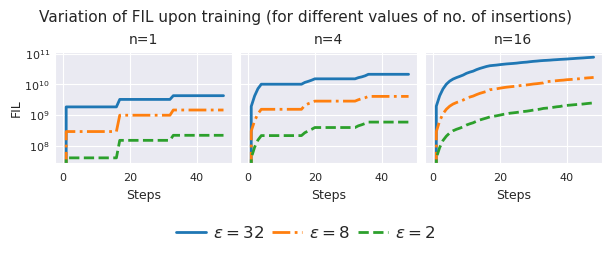

In [ ]:
import matplotlib.lines as mlines

n_values = ['1', '4', '16']
eps_keys = ['ε=32', 'ε=8', 'ε=2']

epsilon_style_map = {
    'ε=32': {'color': 'C0', 'linestyle': '-',   'linewidth': 2},
    'ε=8':  {'color': 'C1', 'linestyle': '-.',  'linewidth': 2},
    'ε=2':  {'color': 'C2', 'linestyle': '--',  'linewidth': 2},
}

eps_latex_map = {
    'ε=32': r'$\epsilon = 32$',
    'ε=8':  r'$\epsilon = 8$',
    'ε=2':  r'$\epsilon = 2$'
}

fig, axs = plt.subplots(1, 3, figsize=(6, 2), sharey=True, constrained_layout=True)

for i, n in enumerate(n_values):
    ax = axs[i]
    for eps in eps_keys:
        for label in ycols_FIL:
            if f'Num={n},' in label:
                if eps == 'No DP' and 'No DP' in label:
                    ax.plot(train_df[xcol], train_df[label],
                            label=r'$\epsilon = \infty$',
                            **epsilon_style_map[eps])
                elif eps in label.replace('epsilon=', 'ε='):
                    ax.plot(train_df[xcol], train_df[label],
                            label=eps_latex_map[eps],
                            **epsilon_style_map[eps])

    ax.set_yscale('log')
    ax.set_title(f'n={n}', fontsize=10)
    ax.set_xlabel('Steps', fontsize=9)
    ax.tick_params(labelsize=8)

    if i == 0:
        ax.set_ylabel('FIL', fontsize=9, labelpad=2)
        ax.yaxis.set_label_coords(-0.18, 0.5)
        ax.yaxis.get_offset_text().set_fontsize(7)
        ax.tick_params(axis='y', pad=0)
    else:
        ax.tick_params(axis='y', labelleft=False)

legend_handles = [
    mlines.Line2D([], [], label=eps_latex_map[eps], **epsilon_style_map[eps])
    for eps in eps_keys
]
fig.suptitle('Variation of FIL upon training (for different values of no. of insertions)', fontsize=11)

fig.legend(handles=legend_handles,
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.25),
           columnspacing=0.5, handlelength=1.8, handletextpad=0.4, frameon=False)

plt.savefig("pdfs_save/FIL_noshuffle_num.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()

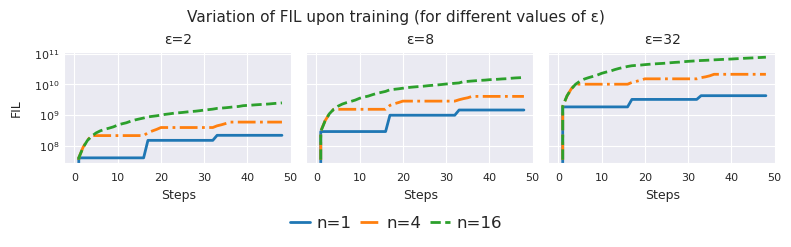

In [ ]:
n_values = ['1', '4', '16']
eps_keys = ['ε=2', 'ε=8', 'ε=32']

n_color_map = {
    '1': {'color': 'C0', 'linestyle': '-',   'linewidth': 2},
    '4': {'color': 'C1', 'linestyle': '-.',  'linewidth': 2},
    '16': {'color': 'C2', 'linestyle': '--', 'linewidth': 2}
}

fig, axs = plt.subplots(1, 3, figsize=(7.8, 2), sharey=True, constrained_layout=True)

for i, eps in enumerate(eps_keys):
    ax = axs[i]
    for n in n_values:
        for label in ycols_FIL:
            if f'Num={n},' in label:
                if eps == 'No DP' and 'No DP' in label:
                    ax.plot(train_df[xcol], train_df[label], label=f'n={n}', **n_color_map[n])
                elif eps in label.replace('epsilon=', 'ε='):
                    ax.plot(train_df[xcol], train_df[label], label=f'n={n}', **n_color_map[n])

    ax.set_title(eps, fontsize=10)
    ax.set_xlabel('Steps', fontsize=9)
    ax.tick_params(labelsize=8)
    ax.set_yscale('log')

    if i == 0:
        ax.set_ylabel('FIL', fontsize=9, labelpad=2)
        ax.yaxis.set_label_coords(-0.18, 0.5)
        ax.yaxis.get_offset_text().set_fontsize(7)
        ax.tick_params(axis='y', pad=0)
    else:
        ax.tick_params(axis='y', labelleft=False)
fig.suptitle('Variation of FIL upon training (for different values of ε)', fontsize=11)

# Legend showing n values
fig.legend([f'n={n}' for n in n_values],
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.2),
           columnspacing=0.5, handlelength=1.2, handletextpad=0.4, frameon=False)

plt.savefig("pdfs_save/FIL_noshuffle_ep.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()


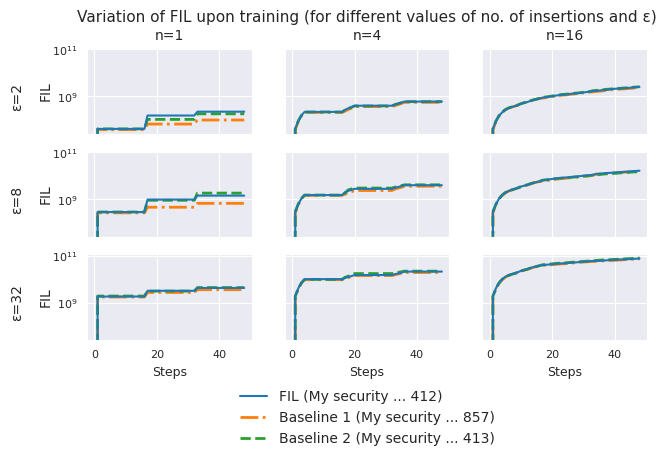

In [ ]:
n_values = ['1', '4', '16']
eps_keys = ['ε=2', 'ε=8', 'ε=32']

plot_styles = {
    'Baseline 857':   {'color': 'C1', 'linestyle': '-.',  'linewidth': 2},
    'Baseline 413':   {'color': 'C2', 'linestyle': '--',  'linewidth': 2},
    'FIL':            {'color': 'C0', 'linestyle': '-',   'linewidth': 1.5}
}

fig, axs = plt.subplots(3, 3, figsize=(7,3.8), sharey=True)
plt.subplots_adjust(left=0.1) 
for row, eps in enumerate(eps_keys):         
    for col, n in enumerate(n_values):       
        ax = axs[row, col]

        # Plot Baseline 857
        for label in ycols_base_857:
            if f'Num={n},' in label and eps in label.replace('epsilon=', 'ε='):
                style = plot_styles['Baseline 857']
                ax.plot(train_df[xcol], train_df[label], label='Baseline 857', **style)

        # Plot Baseline 413
        for label in ycols_base_413:
            if f'Num={n},' in label and eps in label.replace('epsilon=', 'ε='):
                style = plot_styles['Baseline 413']
                ax.plot(train_df[xcol], train_df[label], label='Baseline 413', **style)
        
        for label in ycols_FIL:
            if f'Num={n},' in label and eps in label.replace('epsilon=', 'ε='):
                style = plot_styles['FIL']
                ax.plot(train_df[xcol], train_df[label], label='FIL', **style)

        ax.set_yscale('log', nonpositive='clip')
        ax.yaxis.get_offset_text().set_fontsize(7)
        ax.tick_params(labelsize=8)

        if row == 2:
            ax.set_xlabel('Steps', fontsize=9)
        else:
            ax.tick_params(axis='x', labelbottom=False)

        if col == 0:
            ax.set_ylabel('FIL', fontsize=10, labelpad=15)
            ax.yaxis.set_label_coords(-0.21, 0.5)
        else:
            ax.tick_params(axis='y', labelleft=False)

        if row == 0:
            ax.set_title(f'n={n}', fontsize=10)
for row, eps in enumerate(eps_keys):
    fig.text(0.01, 0.75 - row * 0.27, eps, va='center', ha='right', fontsize=10, rotation=90)

handles = [
    plt.Line2D([0], [0], **plot_styles['FIL'], label='FIL'),
    plt.Line2D([0], [0], **plot_styles['Baseline 857'], label='Baseline 857'),
    plt.Line2D([0], [0], **plot_styles['Baseline 413'], label='Baseline 413'),
]
labels = ['FIL (My security ... 412)', 'Baseline 1 (My security ... 857)', 'Baseline 2 (My security ... 413)']

fig.legend(handles, labels, loc='lower center', ncol=1,
           fontsize=10, bbox_to_anchor=(0.5, -0.2), frameon=False)
fig.suptitle('Variation of FIL upon training (for different values of no. of insertions and ε)', fontsize=11)

plt.savefig("pdfs_save/FIL_no shuffle_baseline.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()


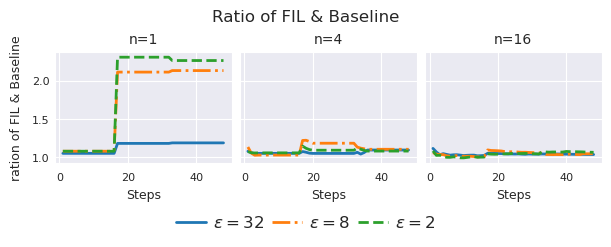

In [ ]:
n_values = ['1', '4', '16']
eps_keys = ['ε=32', 'ε=8', 'ε=2']

epsilon_style_map = {
    'ε=32': {'color': 'C0', 'linestyle': '-',   'linewidth': 2},
    'ε=8':  {'color': 'C1', 'linestyle': '-.',  'linewidth': 2},
    'ε=2':  {'color': 'C2', 'linestyle': '--',  'linewidth': 2},
}

eps_latex_map = {
    'ε=32': r'$\epsilon = 32$',
    'ε=8':  r'$\epsilon = 8$',
    'ε=2':  r'$\epsilon = 2$'
}

fig, axs = plt.subplots(1, 3, figsize=(6, 2), sharey=True, constrained_layout=True)

for i, n in enumerate(n_values):
    ax = axs[i]
    for eps in eps_keys:
        for fil_label in ycols_FIL:
            if f'Num={n},' in fil_label and eps in fil_label.replace('epsilon=', 'ε='):
                # Try to find corresponding baseline_857 label
                matching_baseline = [
                    b for b in ycols_base_857
                    if f'Num={n},' in b and eps in b.replace('epsilon=', 'ε=')
                ]
                if matching_baseline:
                    base_label = matching_baseline[0]
                    ratio = train_df[fil_label] / train_df[base_label]
                    ax.plot(train_df[xcol], ratio,
                            label=eps_latex_map[eps],
                            **epsilon_style_map[eps])

    ax.set_title(f'n={n}', fontsize=10)
    ax.set_xlabel('Steps', fontsize=9)
    ax.tick_params(labelsize=8)

    if i == 0:
        ax.set_ylabel('ration of FIL & Baseline', fontsize=9, labelpad=0)
        ax.yaxis.set_label_coords(-0.18, 0.5)
        ax.yaxis.get_offset_text().set_fontsize(7)
        ax.tick_params(axis='y', pad=0)
    else:
        ax.tick_params(axis='y', labelleft=False)

legend_handles = [
    mlines.Line2D([], [], label=eps_latex_map[eps], **epsilon_style_map[eps])
    for eps in eps_keys
]
fig.suptitle('Ratio of FIL & Baseline',fontsize=12)
fig.legend(handles=legend_handles,
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.2),
           columnspacing=0.5, handlelength=1.8, handletextpad=0.4, frameon=False)

plt.savefig("pdfs_save/FIL_noshuffle_ratio_num.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()


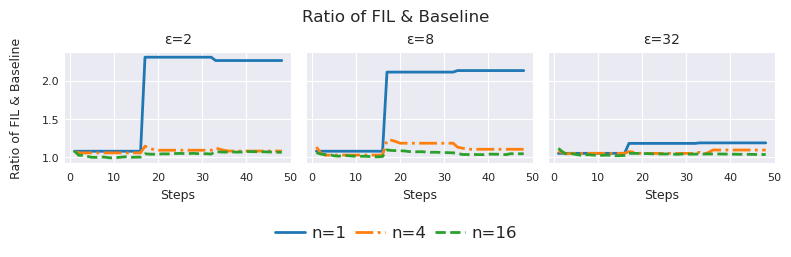

In [ ]:
n_values = ['1', '4', '16']
eps_keys = ['ε=2', 'ε=8', 'ε=32']

n_style_map = {
    '1': {'color': 'C0', 'linestyle': '-',   'linewidth': 2},
    '4': {'color': 'C1', 'linestyle': '-.',  'linewidth': 2},
    '16': {'color': 'C2', 'linestyle': '--', 'linewidth': 2}
}

fig, axs = plt.subplots(1, 3, figsize=(7.8, 2), sharey=True, constrained_layout=True)

for i, eps in enumerate(eps_keys):
    ax = axs[i]
    for n in n_values:
        for fil_label in ycols_FIL:
            if f'Num={n},' in fil_label and eps in fil_label.replace('epsilon=', 'ε='):
                # Find matching Baseline 857 label
                baseline_matches = [
                    base for base in ycols_base_857
                    if f'Num={n},' in base and eps in base.replace('epsilon=', 'ε=')
                ]
                if baseline_matches:
                    base_label = baseline_matches[0]
                    ratio = train_df[fil_label] / train_df[base_label]
                    ax.plot(train_df[xcol], ratio, label=f'n={n}', **n_style_map[n])

    ax.set_title(eps, fontsize=10)
    ax.set_xlabel('Steps', fontsize=9)
    ax.tick_params(labelsize=8)

    if i == 0:
        ax.set_ylabel('Ratio of FIL & Baseline', fontsize=9)
        ax.yaxis.set_label_coords(-0.18, 0.5)
        ax.yaxis.get_offset_text().set_fontsize(7)
        ax.tick_params(axis='y', pad=0)
    else:
        ax.tick_params(axis='y', labelleft=False)
# Create legend handles with matching styles
legend_handles = [
    mlines.Line2D([], [], label=f'n={n}', **n_style_map[n])
    for n in n_values
]
fig.suptitle('Ratio of FIL & Baseline',fontsize=12)
fig.legend(handles=legend_handles,
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.25),
           columnspacing=0.5, handlelength=1.8, handletextpad=0.4, frameon=False)

# Save or show
plt.savefig("pdfs_save/FIL_noshuffle_ratio_ep.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()

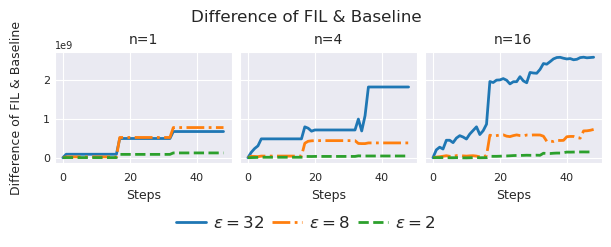

In [ ]:
n_values = ['1', '4', '16']
eps_keys = ['ε=32', 'ε=8', 'ε=2']

epsilon_style_map = {
    'ε=32': {'color': 'C0', 'linestyle': '-',   'linewidth': 2},
    'ε=8':  {'color': 'C1', 'linestyle': '-.',  'linewidth': 2},
    'ε=2':  {'color': 'C2', 'linestyle': '--',  'linewidth': 2},
}

eps_latex_map = {
    'ε=32': r'$\epsilon = 32$',
    'ε=8':  r'$\epsilon = 8$',
    'ε=2':  r'$\epsilon = 2$'
}

fig, axs = plt.subplots(1, 3, figsize=(6, 2), sharey=True, constrained_layout=True)

for i, n in enumerate(n_values):
    ax = axs[i]
    for eps in eps_keys:
        for fil_label in ycols_FIL:
            if f'Num={n},' in fil_label and eps in fil_label.replace('epsilon=', 'ε='):
                matching_baseline = [
                    b for b in ycols_base_857
                    if f'Num={n},' in b and eps in b.replace('epsilon=', 'ε=')
                ]
                if matching_baseline:
                    base_label = matching_baseline[0]
                    ratio = train_df[fil_label] - train_df[base_label]
                    ax.plot(train_df[xcol], ratio,
                            label=eps_latex_map[eps],
                            **epsilon_style_map[eps])

    ax.set_title(f'n={n}', fontsize=10)
    ax.set_xlabel('Steps', fontsize=9)
    ax.tick_params(labelsize=8)

    if i == 0:
        ax.set_ylabel('Difference of FIL & Baseline', fontsize=9, labelpad=0)
        ax.yaxis.set_label_coords(-0.18, 0.5)
        ax.yaxis.get_offset_text().set_fontsize(7)
        ax.tick_params(axis='y', pad=0)
    else:
        ax.tick_params(axis='y', labelleft=False)

legend_handles = [
    mlines.Line2D([], [], label=eps_latex_map[eps], **epsilon_style_map[eps])
    for eps in eps_keys
]
fig.suptitle('Difference of FIL & Baseline',fontsize=12)
fig.legend(handles=legend_handles,
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.2),
           columnspacing=0.5, handlelength=1.8, handletextpad=0.4, frameon=False)

plt.savefig("pdfs_save/FIL_noshuffle_diff_num.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()


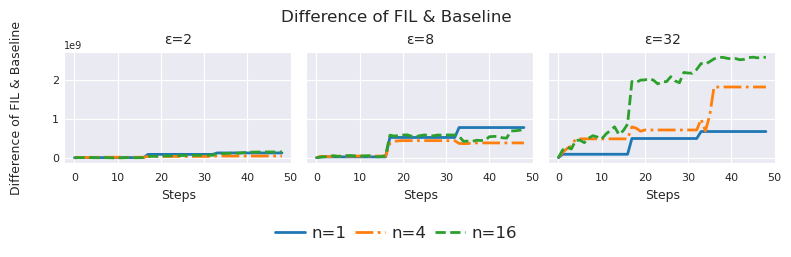

In [ ]:
n_values = ['1', '4', '16']
eps_keys = ['ε=2', 'ε=8', 'ε=32']

n_style_map = {
    '1': {'color': 'C0', 'linestyle': '-',   'linewidth': 2},
    '4': {'color': 'C1', 'linestyle': '-.',  'linewidth': 2},
    '16': {'color': 'C2', 'linestyle': '--', 'linewidth': 2}
}

fig, axs = plt.subplots(1, 3, figsize=(7.8, 2), sharey=True, constrained_layout=True)

for i, eps in enumerate(eps_keys):
    ax = axs[i]
    for n in n_values:
        for fil_label in ycols_FIL:
            if f'Num={n},' in fil_label and eps in fil_label.replace('epsilon=', 'ε='):
                # Find matching Baseline 857 label
                baseline_matches = [
                    base for base in ycols_base_857
                    if f'Num={n},' in base and eps in base.replace('epsilon=', 'ε=')
                ]
                if baseline_matches:
                    base_label = baseline_matches[0]
                    ratio = train_df[fil_label] - train_df[base_label]
                    ax.plot(train_df[xcol], ratio, label=f'n={n}', **n_style_map[n])

    ax.set_title(eps, fontsize=10)
    ax.set_xlabel('Steps', fontsize=9)
    ax.tick_params(labelsize=8)

    if i == 0:
        ax.set_ylabel('Difference of FIL & Baseline', fontsize=9)
        ax.yaxis.set_label_coords(-0.18, 0.5)
        ax.yaxis.get_offset_text().set_fontsize(7)
        ax.tick_params(axis='y', pad=0)
    else:
        ax.tick_params(axis='y', labelleft=False)

legend_handles = [
    mlines.Line2D([], [], label=f'n={n}', **n_style_map[n])
    for n in n_values
]
fig.suptitle('Difference of FIL & Baseline',fontsize=12)
fig.legend(handles=legend_handles,
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.25),
           columnspacing=0.5, handlelength=1.8, handletextpad=0.4, frameon=False)

plt.savefig("pdfs_save/FIL_noshuffle_diff_ep.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()